# ANALISI ESPLORATIVA - LINK PREDICTION IN UNA RETE SOCIALE CON GNN

## 1. Introduzione

Il progetto affronta il problema della link prediction in una rete sociale, con l'obiettivo di stimare quali collegamenti tra nodi potrebbero essere presenti ma ancora non osservati.

Si confrontano metodi euristici basati sulla struttura del grafo con modelli di reti neurali sui grafi.

La valutazione utilizza metriche quali:
 * **ROC-AUC** -> quanto bene il modello riesce a ordinare un arco positivo sopra un arco negativo. Mette il **true positive rate(TPR)** e il **false positive rate(FPR)**, permettendo di interpretarlo come la probabilità che il modello assegni al positivo un punteggio maggiore rispetto al negativo.
 * **Average Precision** -> quanto sono affidabili i collegamenti che modello mette in cima alla classifica. 
 Si utilizza la **precision**, ossia quanto dei positivi sono davvero positivi, e la **recall**, ossia quanto positivi si riescono a catturare in generale.
 L'average precision premia i modelli che riescono a mettere molti collegamenti in alto senza riempire la classifica di falsi positivi.
 * **Hits@K** -> è una metrica legata al recupero dei collegamenti nella parte alta della classifica. In generale, si considerano i primi K candidati ordinati per punteggio e si misura quanti positivi vengono recuperati. 



### 1.1 Caricamento

In [1]:
from config import DATASET_PATH, DATASET_NAME, RESULTS_DIR
from src.data_loader import load_graph
from src.graph_utils import graph_statistics, degree_statistics, plot_degree_distribution, plot_subgraph

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import networkx as nx


print(f"Dataset: {DATASET_NAME}")
print(f"Percorso: {DATASET_PATH}")
print(f"Cartella risultati: {RESULTS_DIR}")

Dataset: ca-AstroPh
Percorso: /Users/santolobianco/Desktop/unict/big data/project/data/ca-AstroPh.txt.gz
Cartella risultati: /Users/santolobianco/Desktop/unict/big data/project/results


Per lo studio del problema di link prediction è stato scelto il dataset **ca-AstroPh**, appartenente alla raccolta di reti sociali e scientifiche SNAP.

Il dataset rappresenta una rete di collaborazione scientifica associata agli articolo di astrofica. Nel grafo:
* i **nodi** rappresentano gli autori;
* gli **archi** rappresentano una relazione di collaborazione tra due autori.

La rete viene trattata come un **grafo non orientato**, poichè la coautorialità è una relazione reciproca.

### 1.2 Ispezione

In [2]:
graph = load_graph(DATASET_PATH)

graph_stats = graph_statistics(graph)
degree_stats = degree_statistics(graph)

stats = {
    **graph_stats,
    **degree_stats,
}

display(pd.DataFrame.from_dict(stats, orient="index", columns=["Valore"]))

,Valore
nodes,18772.000000
edges,198050.000000
density,0.001124
connected_components,290.000000
min_degree,0.000000
max_degree,504.000000
average_degree,21.100575
median_degree,9.000000


La *densità molto bassa* indica che soltanto una piccola frazione dei collegamenti possibili è effettivamente presente.
Questo rende il dataset interessante dato che il problema consiste proprio nell'individuare relazioni plausibili tra nodi che non risultano essere collegati nel grafo osservato.
La *presenza di più componenti connesse* evidenzia che la **rete non è uniformemente connessa**.

## 2. Analisi grafo

### 2.1 Analisi della distribuzione dei gradi

L'*analisi della distribuzione dei gradi* permette di comprendere come sono distribuite le connessioni nella rete e di individuare eventuali differenze tra nodi poco connessi e nodi con un numero elevato di relazioni.

Questa analisi è particolarmente rilevante per la link prediction, poiché le euristiche basate sul grado, come **Preferential Attachment**, possono favorire le relazioni che coinvolgono nodi già molto connessi.

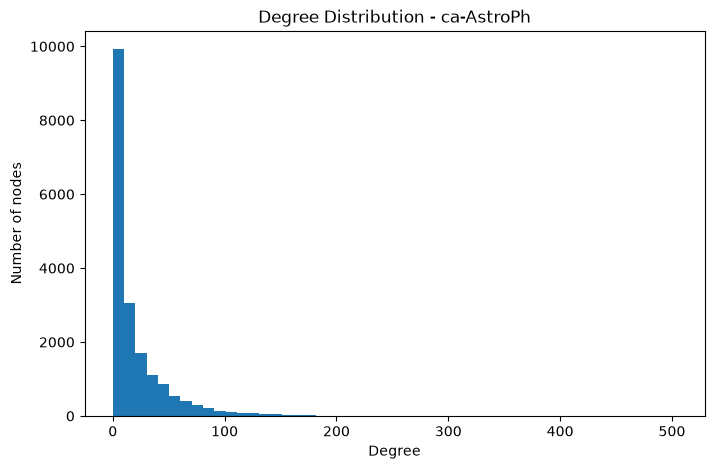

In [3]:

plot_degree_distribution(
    graph,
    title=f"Degree Distribution - {DATASET_NAME}",
    show=True,
    save=False,
)


L'istogramma presenta un *picco iniziale nell'intervallo di grado compreso tra 0 e 20*, seguito da un rapido declino della frequenza. La distribuzione mostra inoltre una *coda che si estende verso valori più elevati*. 
Sono presenti alcuni nodi con grado superiore a 180, fino a raggiungere il massimo di 504(sicuramente un outlier).

Nel complesso, la rete presenta una distribuzione delle connessioni non uniforme: la maggior parte dei nodi ha un numero relativamente contenuto di collegamenti, mentre una piccola frazione possiede un grado elevato. 
Questa caratteristica rende interessante confrontare le prestazioni delle diverse euristiche e dei modelli GNN, per valutare quanto la capacità predittiva dipenda dalla struttura locale del grafo e dal grado dei nodi.

### 2.2 Analisi delle componenti connesse

In questa sezione si esplora la topologia globale del grafo analizzando le sue componenti connessi. I modelli basati su GNN apprendono le rappresentazioni dei nodi propagando le informazioni attraverso gli archi(attraverso il meccanismo di *message-passing*).

Se il grafo fosse frammentato in migliaia di piccole componenti connesse isolate, il modello non potrebbe riuscire a scambiare informazioni tra componenti, ergo sarebbe difficile prevedere nuovi link.

Nel seguente blocco di codice verifichiamo la coesione della rete calcolando quante componenti isolate esistono e, soprattutto, se emerge una macro-struttura dominante(**Giant Component**) in grado di sostenere l'addestramento della GNN.

In [4]:
components = sorted(
    nx.connected_components(graph),
    key=len,
    reverse=True,
)

component_sizes = [len(component) for component in components]

print("Numero di componenti:", len(components))
print("Dimensione della componente principale:", component_sizes[0])
print("Dimensione delle prime 10 componenti:", component_sizes[:10])
print(
    "Percentuale di nodi nella componente principale:",
    round(100 * component_sizes[0] / graph.number_of_nodes(), 2),
    "%",
)

Numero di componenti: 290
Dimensione della componente principale: 17903
Dimensione delle prime 10 componenti: [17903, 18, 12, 10, 10, 9, 8, 8, 8, 7]
Percentuale di nodi nella componente principale: 95.37 %


L'analisi topologica mostra una caratteristica fondamentale delle reti sociali reali: la presenza di una **Componente Gigante**. 

Come si evince dall'output, sebbene il grafo sia frammentato in 290 componenti distinte, la componente principale assorbe da sola il **95.37% dell'intera rete**. Le restanti 289 componenti sono di dimensioni trascurabili, al massimo composte da 18 nodi. 

Questo scenario è ideale per il task di Link Prediction: garantisce che le euristiche basate sui cammini, come **Common Neighbors** e **Adamic-Adar**, e il meccanismo di *message-passing* della GNN possano operare efficacemente sulla quasi totalità dei nodi, potendo sfruttare un'unica macro-struttura interconnessa.

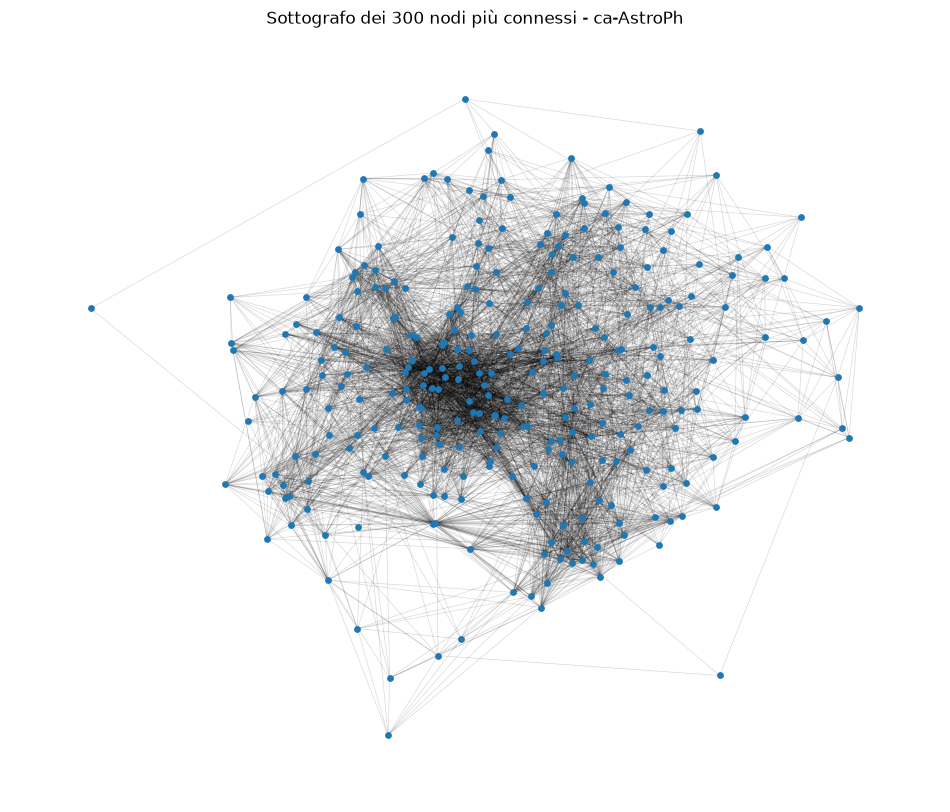

Nodi visualizzati: 300
Archi visualizzati: 5718


In [5]:
subgraph = plot_subgraph(
    graph,
    top_n=300,
    seed=42,
    title= f"Sottografo dei 300 nodi più connessi - {DATASET_NAME}",
    show=True,
    save=False
)
print("Nodi visualizzati:", subgraph.number_of_nodes())
print("Archi visualizzati:", subgraph.number_of_edges())

Estraendo il sottografo dei soli **300 nodi a grado più elevato** (i top 300 "Hub" della rete), emerge una struttura densissima.

Questi 300 autori, da soli, formano ben **5.718 archi**, creando un nucleo centrale in cui quasi tutti collaborano con tutti. 

Questa visualizzazione conferma due dinamiche importanti:
1. **Effetto Rich-Club (o Preferential Attachment):** i nodi molto popolari tendono a connettersi massicciamente con altri nodi popolari.
2. **Elevato Clustering Localizzato:** esistono comunità di co-autoraggio estremamente chiuse e coese.

### 2.3 Coeefficiente di Clustering e densità

Il **coefficiente di clustering** misura la tendenza dei vicini di un nodo ad essere collegati tra loro.
In una rete di autori, se gli autori collaborano con uno stesso autore tendono anche a condividere collaborazioni reciproche.

Un **coefficiente elevato di clustering** indica una **maggiore presenza di triangoli** nella rete, ossia gruppi di tre nodi in cui ogni nodo è collegato agli altri due.



In [6]:
clustering_coefficients = nx.clustering(graph)

clustering_values = list(clustering_coefficients.values())

clustering_stats = {
    "average_clustering": nx.average_clustering(graph),
    "nodes_with_zero_clustering": sum(
        value == 0 for value in clustering_values
    ),
    "nodes_with_positive_clustering": sum(
        value > 0 for value in clustering_values
    ),
}

display(pd.DataFrame(
    clustering_stats.items(),
    columns=["Metrica", "Valore"]
))

,Metrica,Valore
0,average_clustering,0.630593
1,nodes_with_zero_clustering,1386.000000
2,nodes_with_positive_clustering,17386.000000


Il **coefficiente medio di clustering della rete** è pari a circa **0,6306**, indicando una significativa tendenza alla formazione di gruppi locali in cui i vicini dei nodi sono collegati tra loro. 
Nella rete di coautorialità, questo fenomeno è compatibile con la presenza di gruppi di autori che condividono collaborazioni.

Su 18.772 nodi complessivi, 17.386 presentano un coefficiente di clustering positivo, mentre 1.386 hanno coefficiente pari a zero. 

La prevalenza di nodi con clustering positivo evidenzia l'importanza della struttura locale della rete. 

Le relazioni tra vicini comuni possono fornire informazioni utili per individuare potenziali collegamenti mancanti.

In [7]:
density = graph_stats["density"]

print(f"Densità del grafo: {density:.6f}")
print(f"Percentuale di connessioni possibili presenti: {density * 100:.4f}%")
print(f"Percentuale di connessioni possibili assenti: {(1 - density) * 100:.4f}%")

Densità del grafo: 0.001124
Percentuale di connessioni possibili presenti: 0.1124%
Percentuale di connessioni possibili assenti: 99.8876%


La rete presenta una **densità** pari a circa **0,001124** corrispondente allo 0,1124% delle connessioni possibili. Si tratta quindi di un **grafo fortemente sparso**, nel quale **la maggior parte delle coppie di nodi non è collegata direttamente**.

Questa caratteristica è rilevante per la link prediction: l'assenza di un arco non implica necessariamente una relazione negativa reale, poiché il collegamento potrebbe non essere osservato nel dataset. 

## 3. Analisi Baseline vs GNN

### 3.1 Confronto globale ROC AUC e Average Precision

In questa sezione vengono analizzati i risultati degli esperimenti condotti sul dataset ca-AstroPh, con l'obiettivo di confrontare le prestazioni delle baseline euristiche con quelle dei modelli basati su GNN.

L'analisi utilizza i risultati già salvati nei file CSV, senza ripetere l'addestramento dei modelli.

Viene effettuato un confronto globale basato sulle metriche ROC-AUC e Average Precision(AP), per valutare la capacità di diversi approcci di distinguere gli archi reali da quelli campionati come negativi.

In [8]:
baseline_path = RESULTS_DIR / f"{DATASET_NAME}_baseline_results.csv"
gnn_summary_path = RESULTS_DIR / f"{DATASET_NAME}_gnn_decoder_summary.csv"
gnn_results_path = RESULTS_DIR / f"{DATASET_NAME}_gnn_decoder_results.csv"

baseline_df = pd.read_csv(baseline_path)
gnn_summary_df = pd.read_csv(gnn_summary_path)
gnn_results_df = pd.read_csv(gnn_results_path)

print("=== BASELINE EURISTICHE ===")
display(baseline_df)

print("=== RIEPILOGO GNN ===")
display(gnn_summary_df)

print("=== SINGOLE ESECUZIONI GNN ===")
display(gnn_results_df)

=== BASELINE EURISTICHE ===


,dataset,graph,baseline,auc,ap,hits@10,hits@50,hits@100
0,ca-AstroPh,train_graph,Common Neighbors,0.982713,0.982302,0.853,0.940,0.960
1,ca-AstroPh,train_graph,Jaccard,0.982800,0.982702,0.905,0.958,0.962
2,ca-AstroPh,train_graph,Adamic-Adar,0.983305,0.983498,0.905,0.957,0.962
3,ca-AstroPh,train_graph,Preferential Attachment,0.861947,0.873136,0.051,0.179,0.321
4,ca-AstroPh,message_passing_graph,Common Neighbors,0.975049,0.974661,0.828,0.928,0.952
5,ca-AstroPh,message_passing_graph,Jaccard,0.975029,0.974852,0.881,0.950,0.952
6,ca-AstroPh,message_passing_graph,Adamic-Adar,0.975614,0.975882,0.882,0.947,0.953
7,ca-AstroPh,message_passing_graph,Preferential Attachment,0.861514,0.872632,0.051,0.180,0.317


=== RIEPILOGO GNN ===


,dataset,decoder,num_seeds,val_auc_mean,val_auc_std,val_ap_mean,val_ap_std,test_auc_mean,test_auc_std,test_ap_mean,test_ap_std,hits@10_mean,hits@10_std,hits@50_mean,hits@50_std,hits@100_mean,hits@100_std
0,ca-AstroPh,mlp,5,0.948060,0.000259,0.947801,0.000281,0.948031,0.000309,0.948665,0.000256,0.2310,0.002280,0.4954,0.005044,0.6498,0.005776
1,ca-AstroPh,dot_product,5,0.901319,0.002109,0.907581,0.001763,0.902304,0.002255,0.908511,0.002060,0.1082,0.004069,0.3798,0.012576,0.5548,0.007332


=== SINGOLE ESECUZIONI GNN ===


,dataset,decoder,seed,best_epoch,epochs_trained,val_auc,val_ap,test_auc,test_ap,hits@10,hits@50,hits@100
0,ca-AstroPh,mlp,1,499,500,0.948327,0.947901,0.948388,0.948893,0.227,0.488,0.639
1,ca-AstroPh,mlp,2,500,500,0.948104,0.948139,0.947883,0.948742,0.234,0.493,0.655
2,ca-AstroPh,mlp,3,500,500,0.948306,0.947983,0.948395,0.948962,0.232,0.500,0.649
3,ca-AstroPh,mlp,4,500,500,0.947628,0.947342,0.947620,0.948363,0.231,0.502,0.652
4,ca-AstroPh,mlp,5,500,500,0.947936,0.947638,0.947867,0.948366,0.231,0.494,0.654
5,ca-AstroPh,dot_product,1,500,500,0.898714,0.905306,0.899973,0.906187,0.102,0.365,0.547
6,ca-AstroPh,dot_product,2,500,500,0.898767,0.905591,0.899159,0.905847,0.105,0.365,0.545
7,ca-AstroPh,dot_product,3,500,500,0.903261,0.909063,0.904251,0.910304,0.110,0.390,0.560
8,ca-AstroPh,dot_product,4,499,500,0.902910,0.908562,0.903892,0.909671,0.113,0.384,0.559
9,ca-AstroPh,dot_product,5,500,500,0.902940,0.909381,0.904247,0.910549,0.111,0.395,0.563


Osservando la tabella *baseline_df*, si nota che le euristiche sono state valutate su due grafi differenti: **train_graph** e **message_passing_graph**.

La distinzione viene fatta perchè:
- il **train_graph** contiene tutti gli archi disponibili per l'addestramento. Le euristiche classiche lo utilizzano per ottenere le massime prestazioni.
- la **GNN**, richiede un **partizionamento interno (supervisione vs. message-passing)** per calcolare la funzione di loss e non incappare in *data leakage*. Di conseguenza, la GNN costruisce le rappresentazioni dei nodi osservando **solo** il message_passing_graph (sottoinsieme del train_graph).

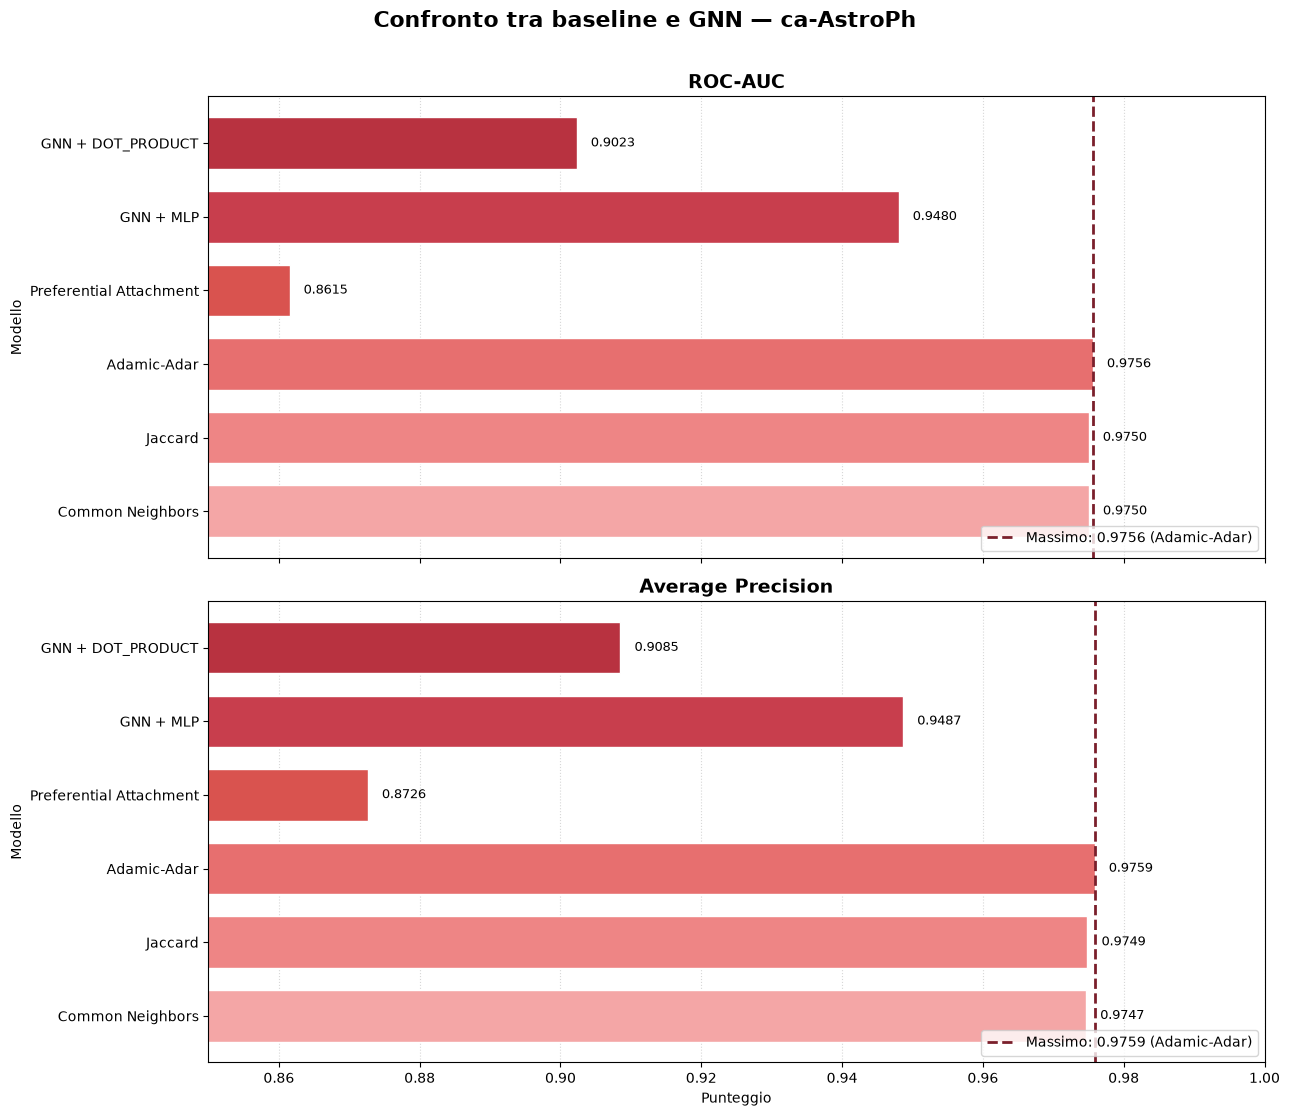

In [9]:
# Baseline valutate sul message_passing_graph
baseline_fair = baseline_df[
    baseline_df["graph"] == "message_passing_graph"
].copy()

# Prepara i dati
baseline_labels = baseline_fair["baseline"].tolist()
baseline_auc = baseline_fair["auc"].tolist()
baseline_ap = baseline_fair["ap"].tolist()

gnn_labels = [
    f"GNN + {decoder.upper()}"
    for decoder in gnn_summary_df["decoder"]
]
gnn_auc = gnn_summary_df["test_auc_mean"].tolist()
gnn_ap = gnn_summary_df["test_ap_mean"].tolist()

labels = baseline_labels + gnn_labels
auc_scores = baseline_auc + gnn_auc
ap_scores = baseline_ap + gnn_ap

# Massimi
max_auc_idx = np.argmax(auc_scores)
max_ap_idx = np.argmax(ap_scores)

max_auc = auc_scores[max_auc_idx]
max_ap = ap_scores[max_ap_idx]

# Palette corallo/rossa
colors = [
    "#F4A6A6",
    "#EE8585",
    "#E76F6F",
    "#D9534F",
    "#C83E4D",
    "#B83240",
]

# Due grafici verticali, entrambi a tutta larghezza
fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 11),
    sharex=True
)

# -------------------------
# 1. ROC-AUC
# -------------------------
axes[0].barh(
    labels,
    auc_scores,
    color=colors[:len(labels)],
    edgecolor="white",
    height=0.7
)

axes[0].axvline(
    max_auc,
    color="#7A1F2B",
    linestyle="--",
    linewidth=2,
    label=f"Massimo: {max_auc:.4f} ({labels[max_auc_idx]})"
)

axes[0].set_title("ROC-AUC", fontsize=14, weight="bold")
axes[0].set_ylabel("Modello")
axes[0].set_xlim(0.85, 1.00)
axes[0].grid(axis="x", linestyle=":", alpha=0.5)
axes[0].set_axisbelow(True)
axes[0].legend(loc="lower right")

for i, value in enumerate(auc_scores):
    axes[0].text(
        value + 0.002, i,
        f"{value:.4f}",
        va="center",
        fontsize=9
    )

# -------------------------
# 2. Average Precision
# -------------------------
axes[1].barh(
    labels,
    ap_scores,
    color=colors[:len(labels)],
    edgecolor="white",
    height=0.7
)

axes[1].axvline(
    max_ap,
    color="#7A1F2B",
    linestyle="--",
    linewidth=2,
    label=f"Massimo: {max_ap:.4f} ({labels[max_ap_idx]})"
)

axes[1].set_title("Average Precision", fontsize=14, weight="bold")
axes[1].set_xlabel("Punteggio")
axes[1].set_ylabel("Modello")
axes[1].set_xlim(0.85, 1.00)
axes[1].grid(axis="x", linestyle=":", alpha=0.5)
axes[1].set_axisbelow(True)
axes[1].legend(loc="lower right")

for i, value in enumerate(ap_scores):
    axes[1].text(
        value + 0.002, i,
        f"{value:.4f}",
        va="center",
        fontsize=9
    )

fig.suptitle(
    f"Confronto tra baseline e GNN — {DATASET_NAME}",
    fontsize=16,
    weight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

I risultati mostrano che le euristiche basate sui vicini condivisi sono particolarmente efficaci sul dataset `ca-AstroPh`. 

In particolare, **Adamic-Adar** ottiene le migliori prestazioni tra le baseline valutate sul `message_passing_graph`, con un'AUC pari a **0.9756** e un'AP pari a **0.9759**. Questi risultati sono coerenti con l'importanza della chiusura triadica nelle reti di co-autoraggio: autori che condividono collaboratori hanno un'altissima probabilità di collaborare a loro volta.

Al contrario, **Preferential Attachment** raggiunge valori significativamente inferiori (AUC **0.8615** e AP **0.8726**), suggerendo che la sola popolarità (il grado dei nodi) sia meno informativa, in questo contesto, rispetto alla struttura delle relazioni locali.

Tra i modelli neurali, **GraphSAGE con decoder MLP** ottiene risultati nettamente migliori rispetto alla variante con decoder Dot Product (AUC **0.9480** contro **0.8996**; AP **0.9487** contro **0.9060**). La maggiore flessibilità dell'MLP consente di modellare relazioni non lineari complesse tra gli embedding dei nodi. 

Tuttavia, in questo specifico task di classificazione, entrambe le varianti GNN rimangono al di sotto delle migliori euristiche locali, dimostrando come, per reti così densamente raggruppate, la struttura locale fornisca già un'informazione predittiva formidabile.

### 3.2 Analisi delle Metriche di Ranking

Oltre alla capacità di distinguere gli archi reali dai campioni negativi, è importante valutare quanto efficacemente un modello riesca a classificare gli archi positivi nelle prime posizioni di una graduatoria.

A questo scopo utilizziamo le metriche **Hits@10, Hits@50 e Hits@100**, che misurano la proporzione di archi positivi collocati entro le prime \(K\) posizioni secondo il protocollo di ranking adottato.

Valori più elevati indicano una maggiore capacità di recuperare i collegamenti corretti nelle prime posizioni. Queste metriche completano l'analisi basata su ROC-AUC e Average Precision, offrendo una prospettiva più vicina agli scenari applicativi di raccomandazione dei collegamenti.

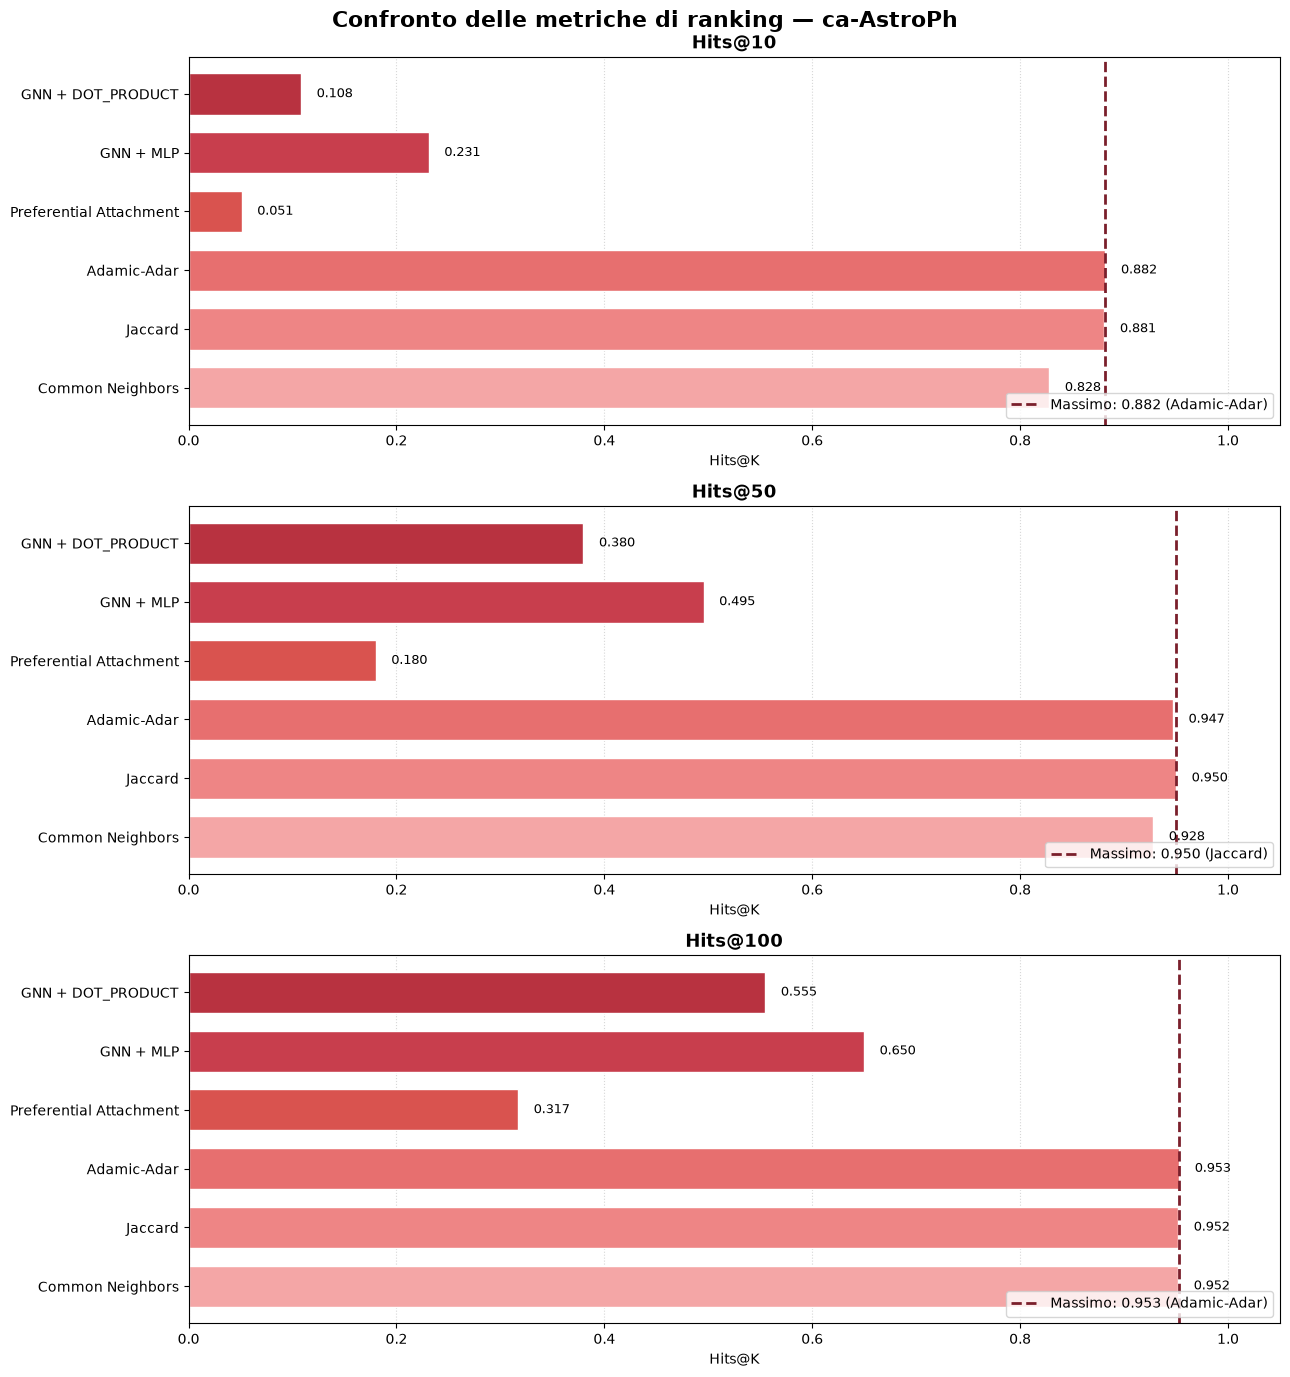

In [11]:
# Baseline valutate sul message_passing_graph
baseline_fair = baseline_df[
    baseline_df["graph"] == "message_passing_graph"
].copy()

# Nomi dei modelli
baseline_labels = baseline_fair["baseline"].tolist()
gnn_labels = [
    f"GNN + {decoder.upper()}"
    for decoder in gnn_summary_df["decoder"]
]

labels = baseline_labels + gnn_labels

# Valori Hits@K: baseline
hits10 = baseline_fair["hits@10"].tolist()
hits50 = baseline_fair["hits@50"].tolist()
hits100 = baseline_fair["hits@100"].tolist()

# Valori Hits@K: GNN, medie sui cinque seed
hits10 += gnn_summary_df["hits@10_mean"].tolist()
hits50 += gnn_summary_df["hits@50_mean"].tolist()
hits100 += gnn_summary_df["hits@100_mean"].tolist()

# Grafici orizzontali impilati verticalmente
fig, axes = plt.subplots(3, 1, figsize=(13, 14))

metrics = [
    ("Hits@10", hits10),
    ("Hits@50", hits50),
    ("Hits@100", hits100),
]

colors = [
    "#F4A6A6",
    "#EE8585",
    "#E76F6F",
    "#D9534F",
    "#C83E4D",
    "#B83240",
]

for ax, (metric_name, values) in zip(axes, metrics):
    max_idx = np.argmax(values)
    max_value = values[max_idx]

    ax.barh(
        labels,
        values,
        color=colors[:len(labels)],
        edgecolor="white",
        height=0.7
    )

    ax.axvline(
        max_value,
        color="#7A1F2B",
        linestyle="--",
        linewidth=2,
        label=f"Massimo: {max_value:.3f} ({labels[max_idx]})"
    )

    ax.set_title(metric_name, fontsize=13, weight="bold")
    ax.set_xlabel("Hits@K")
    ax.set_xlim(0, 1.05)
    ax.grid(axis="x", linestyle=":", alpha=0.5)
    ax.set_axisbelow(True)
    ax.legend(loc="lower right")

    for i, value in enumerate(values):
        ax.text(
            value + 0.015,
            i,
            f"{value:.3f}",
            va="center",
            fontsize=9
        )

fig.suptitle(
    f"Confronto delle metriche di ranking — {DATASET_NAME}",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()
plt.show()

L'analisi delle metriche Hits@10, Hits@50 e Hits@100 mostra un vantaggio delle euristiche basate sui vicini condivisi rispetto alle altre baseline e alle varianti GNN considerate. In particolare, **Adamic-Adar e Jaccard** ottengono i risultati migliori: Adamic-Adar raggiunge 0,882 in Hits@10 e 0,953 in Hits@100, mentre Jaccard raggiunge il valore massimo di 0,950 in Hits@50.

Tra i modelli neurali, **GraphSAGE con decoder MLP** supera costantemente la variante con decoder *dot product*, ottenendo rispettivamente 0,231, 0,495 e 0,650 nelle tre metriche. Anche il decoder dot product migliora all'aumentare di K, ma mantiene prestazioni inferiori. Il Preferential Attachment presenta i risultati più bassi tra i metodi confrontati.

Nel complesso, all'aumentare di K cresce la quota di collegamenti positivi recuperati nelle prime posizioni della graduatoria. Le euristiche locali rimangono particolarmente competitive sul dataset `ca-AstroPh`, mentre tra le varianti GNN il decoder MLP si dimostra più efficace. Il confronto va interpretato considerando il protocollo di ranking adottato e le differenze nell'informazione topologica disponibile.

### 3.3 Feature Ablation

La feature ablation è un'analisi sperimentale che permette di valutare il contributo delle singole caratteristiche in ingresso a un modello. In questo esperimento vengono confrontate diverse configurazioni di GraphSAGE, utilizzando il grado dei nodi, il coefficiente di clustering, entrambe le feature oppure valori costanti. L'obiettivo è comprendere quanto queste informazioni strutturali influenzino le prestazioni del modello nella link prediction.

In [14]:

ablation_path = RESULTS_DIR / f"{DATASET_NAME}_feature_ablation_results.csv"
ablation_df = pd.read_csv(ablation_path)

display(ablation_df)


,dataset,feature_mode,input_features,best_epoch,epochs_trained,val_auc,val_ap,test_auc,test_ap
0,ca-AstroPh,full,2,400,400,0.954771,0.955007,0.953229,0.953652
1,ca-AstroPh,degree,1,400,400,0.934220,0.936091,0.935032,0.936928
2,ca-AstroPh,clustering,1,396,400,0.930693,0.926203,0.930387,0.926586
3,ca-AstroPh,constant,1,8,58,0.438870,0.519680,0.438130,0.516697


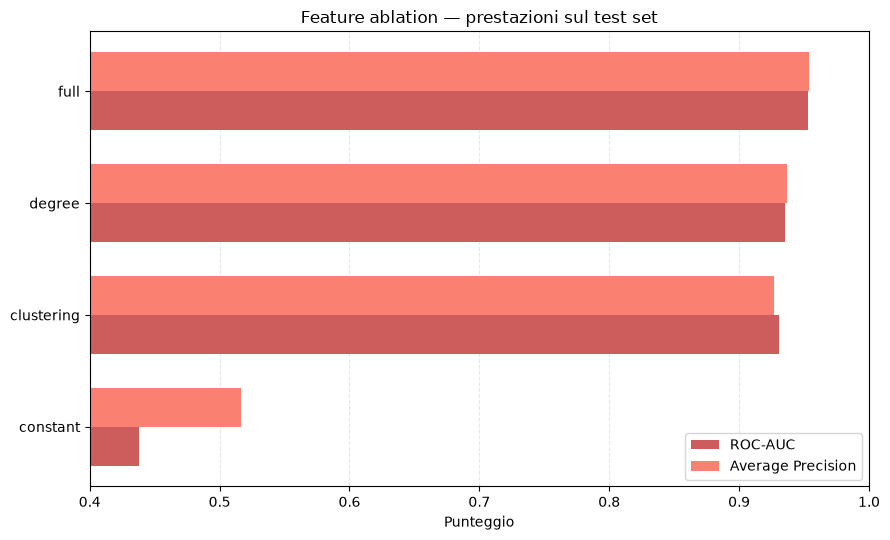

In [15]:
# Metriche sul test set
plot_df = ablation_df.sort_values("test_auc", ascending=True).copy()

labels = plot_df["feature_mode"].tolist()
y = np.arange(len(labels))
height = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.barh(
    y - height / 2,
    plot_df["test_auc"],
    height,
    label="ROC-AUC",
    color="indianred"
)

ax.barh(
    y + height / 2,
    plot_df["test_ap"],
    height,
    label="Average Precision",
    color="salmon"
)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlim(0.40, 1.00)
ax.set_xlabel("Punteggio")
ax.set_title("Feature ablation — prestazioni sul test set")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.legend()
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


L'analisi di feature ablation permette di valutare il contributo delle caratteristiche iniziali dei nodi alle prestazioni del modello GraphSAGE. Sono state confrontate quattro configurazioni: `full`, che utilizza sia il grado normalizzato sia il coefficiente di clustering; `degree`, che utilizza soltanto il grado; `clustering`, che utilizza soltanto il coefficiente di clustering; e `constant`, che impiega feature costanti, prive di informazioni strutturali specifiche per ciascun nodo.

La configurazione **`full` ottiene i risultati migliori**, con ROC-AUC pari a 0,9532 e Average Precision pari a 0,9537 sul test set. Le configurazioni `degree` e `clustering` raggiungono rispettivamente ROC-AUC di 0,9350 e 0,9304, con Average Precision pari a 0,9369 e 0,9266. Questi risultati suggeriscono che entrambe le feature contribuiscono alla capacità predittiva del modello e che il loro utilizzo congiunto è più efficace rispetto al loro impiego separato, nelle condizioni sperimentali considerate.

La configurazione `constant` presenta prestazioni nettamente inferiori, con ROC-AUC pari a 0,4381 e Average Precision pari a 0,5167. Questo risultato evidenzia che, nella configurazione sperimentata, fornire informazioni strutturali specifiche sui nodi è importante per apprendere rappresentazioni utili alla previsione degli archi. Le prestazioni della configurazione `constant` sono inferiori anche a quelle attese da un modello discriminante efficace; in particolare, la ROC-AUC inferiore a 0,5 indica una capacità di ordinamento dei collegamenti peggiore di quella casuale sul test set.

Per tutte le configurazioni è stato previsto un limite massimo di 400 epoche e un meccanismo di *early stopping* con `patience=50`, basato sull'assenza di miglioramenti della ROC-AUC sul validation set. Le configurazioni `full` e `degree` hanno raggiunto il limite massimo di 400 epoche, mentre `clustering` si è fermata all'epoca 396 e `constant` all'epoca 58. Quest'ultima interruzione è coerente con il criterio di arresto anticipato: il modello ha smesso di migliorare sul validation set per il numero di epoche consecutive previsto. L'arresto anticipato non implica, di per sé, un confronto scorretto, poiché fa parte della procedura di addestramento adottata.

Nel complesso, l'esperimento mostra che **l'impiego congiunto del grado e del coefficiente di clustering costituisce la scelta più efficace tra le configurazioni valutate** su `ca-AstroPh`. I risultati vanno comunque interpretati entro i limiti dell'esperimento: il confronto riguarda specifiche feature e un singolo dataset e non dimostra che la stessa combinazione sia ottimale su altre reti o con architetture differenti.

### 3.4 Analisi del degree Bias

Il *degree bias* riguarda la possibile dipendenza delle prestazioni di un metodo dal grado dei nodi coinvolti nella previsione dei collegamenti. In questa analisi, i risultati vengono esaminati suddividendo gli archi positivi in gruppi in base al grado dei nodi, per verificare se le euristiche considerate riescano a identificare efficacemente collegamenti associati a nodi con diversa connettività. L'obiettivo è individuare eventuali differenze nelle prestazioni e discutere i possibili limiti dei metodi di link prediction.

In [17]:

degree_bias_path = RESULTS_DIR / f"{DATASET_NAME}_degree_bias_results.csv"
degree_bias_df = pd.read_csv(degree_bias_path)

print("=== RISULTATI DEGREE BIAS ===")
display(degree_bias_df)


=== RISULTATI DEGREE BIAS ===


,dataset,baseline,quartile,positive_edges,negative_edges,auc,ap
0,ca-AstroPh,Common Neighbors,Q1,1528,8398,0.919994,0.860834
1,ca-AstroPh,Common Neighbors,Q2,3389,6656,0.970641,0.959927
2,ca-AstroPh,Common Neighbors,Q3,6143,3638,0.987339,0.990415
3,ca-AstroPh,Common Neighbors,Q4,8745,1113,0.992221,0.998523
4,ca-AstroPh,Jaccard,Q1,1528,8398,0.920046,0.862394
5,ca-AstroPh,Jaccard,Q2,3389,6656,0.970697,0.960882
6,ca-AstroPh,Jaccard,Q3,6143,3638,0.987544,0.991079
7,ca-AstroPh,Jaccard,Q4,8745,1113,0.992213,0.998664
8,ca-AstroPh,Adamic-Adar,Q1,1528,8398,0.920181,0.863913
9,ca-AstroPh,Adamic-Adar,Q2,3389,6656,0.971009,0.961628


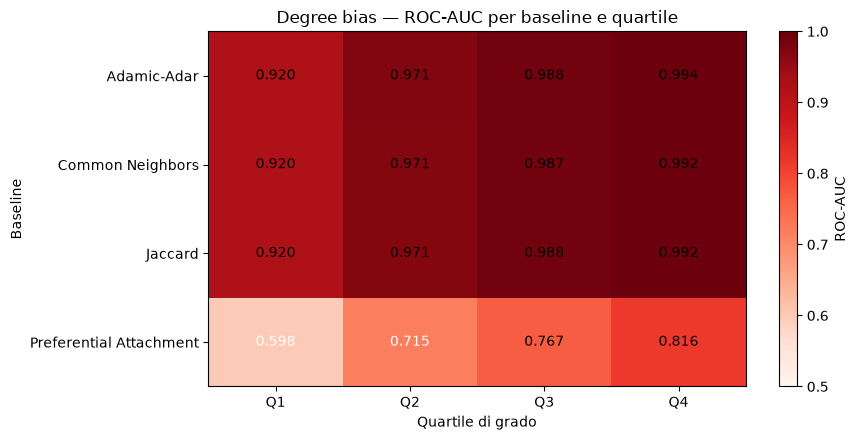

In [18]:
# Preparazione della matrice: baseline x quartile
auc_pivot = degree_bias_df.pivot(
    index="baseline",
    columns="quartile",
    values="auc"
)

# Manteniamo l'ordine naturale dei quartili
auc_pivot = auc_pivot[["Q1", "Q2", "Q3", "Q4"]]

fig, ax = plt.subplots(figsize=(9, 4.5))

im = ax.imshow(
    auc_pivot.values,
    cmap="Reds",
    aspect="auto",
    vmin=0.5,
    vmax=1.0
)

ax.set_xticks(np.arange(len(auc_pivot.columns)))
ax.set_xticklabels(auc_pivot.columns)
ax.set_yticks(np.arange(len(auc_pivot.index)))
ax.set_yticklabels(auc_pivot.index)

# Valori nelle celle
for i in range(auc_pivot.shape[0]):
    for j in range(auc_pivot.shape[1]):
        value = auc_pivot.iloc[i, j]
        ax.text(
            j, i, f"{value:.3f}",
            ha="center", va="center",
            color="white" if value < 0.75 else "black"
        )

ax.set_title("Degree bias — ROC-AUC per baseline e quartile")
ax.set_xlabel("Quartile di grado")
ax.set_ylabel("Baseline")

fig.colorbar(im, ax=ax, label="ROC-AUC")
plt.tight_layout()
plt.show()


L'analisi mostra una relazione tra il quartile di grado considerato e le prestazioni delle euristiche. Per Common Neighbors, Jaccard e Adamic-Adar, la ROC-AUC aumenta progressivamente da Q1 a Q4. Adamic-Adar passa da 0,9202 in Q1 a 0,9936 in Q4, mentre Common Neighbors e Jaccard raggiungono valori analogamente elevati nel quartile superiore.

Questo andamento suggerisce che le euristiche basate sulla struttura dei vicini condivisi distinguono più efficacemente gli archi positivi dai negativi nei gruppi associati a nodi con grado più elevato. Una possibile spiegazione è che i nodi più connessi offrano più informazioni sulle relazioni locali. Il risultato va comunque interpretato nel contesto della specifica suddivisione in quartili utilizzata.

Preferential Attachment presenta prestazioni inferiori in termini di ROC-AUC in tutti i quartili, passando da 0,5985 in Q1 a 0,8155 in Q4. Anche per questa euristica si osserva quindi un miglioramento al crescere del quartile, ma la capacità discriminante rimane inferiore a quella delle altre tre baseline.

È importante considerare anche il numero di archi positivi e negativi nei diversi gruppi: Q1 contiene 1.528 archi positivi e 8.398 negativi, mentre Q4 contiene 8.745 positivi e 1.113 negativi. Questa differenza nella composizione dei gruppi può influenzare l'interpretazione delle metriche, in particolare dell'Average Precision, che dipende dalla prevalenza dei positivi.

Nel complesso, i risultati evidenziano che le prestazioni delle euristiche non sono uniformi tra i quartili. L'analisi del degree bias aiuta quindi a individuare possibili differenze di comportamento dei metodi in funzione della connettività dei nodi, senza implicare necessariamente un rapporto causale tra grado e capacità predittiva.

## 4. Considerazioni etiche, privacy e limiti

La link prediction può essere utile per individuare collaborazioni potenziali e comprendere la struttura di una rete sociale, ma comporta anche alcune criticità. La previsione di un collegamento non osservato potrebbe infatti suggerire relazioni che gli individui non desiderano rendere esplicite. È quindi importante considerare la tutela della privacy e i possibili usi impropri delle previsioni.

Un ulteriore limite riguarda l'interpretazione dei risultati: un arco assente nel grafo non rappresenta necessariamente una relazione inesistente, poiché può trattarsi di un collegamento non osservato o non registrato. Inoltre, le prestazioni dei metodi possono variare in funzione della struttura della rete e del grado dei nodi, come evidenziato dall'analisi del degree bias.

Infine, i risultati ottenuti su ca-AstroPh non garantiscono prestazioni analoghe su altre reti. Le previsioni devono pertanto essere interpretate come stime probabilistiche, non come prove dell'esistenza di una relazione reale. Un utilizzo responsabile richiede trasparenza sui limiti del modello, attenzione ai dati impiegati e cautela nelle decisioni basate sulle sue predizioni.

## 5. Conclusioni

In questo progetto è stato affrontato il problema della link prediction in una rete di co-autorialità, utilizzando il dataset ca-AstroPh. Sono state confrontate diverse euristiche strutturali, tra cui Common Neighbors, Jaccard, Adamic-Adar e Preferential Attachment, con un approccio basato su Graph Neural Networks, implementato mediante GraphSAGE e differenti decoder.

I risultati sperimentali mostrano che le euristiche basate sui vicini condivisi sono particolarmente competitive sul dataset considerato. Tra le varianti neurali, GraphSAGE con decoder MLP ottiene prestazioni migliori rispetto alla variante con decoder dot product. Questi risultati evidenziano che, in questa rete, le informazioni topologiche locali costituiscono una base efficace per prevedere collegamenti mancanti.

L'analisi di feature ablation ha inoltre mostrato che l'utilizzo congiunto del grado normalizzato e del coefficiente di clustering produce risultati migliori rispetto alle configurazioni che impiegano una sola feature o valori costanti. L'analisi del degree bias ha evidenziato differenze nelle prestazioni delle euristiche tra i quartili di grado, sottolineando l'importanza di considerare la struttura della rete nell'interpretazione dei risultati.

Il progetto presenta alcuni limiti. Le valutazioni sono state condotte su un singolo dataset e le prestazioni dipendono dal protocollo sperimentale, dalla selezione dei collegamenti negativi e dalle caratteristiche della rete. Inoltre, un collegamento previsto non implica necessariamente una relazione reale, e l'applicazione della link prediction a reti sociali richiede attenzione alla privacy e ai possibili bias.

In conclusione, il lavoro mostra come sia possibile affrontare la link prediction combinando metodi euristici e modelli basati su GNN, evidenziando vantaggi e limiti dei diversi approcci. Possibili sviluppi futuri includono la valutazione su ulteriori dataset, l'esplorazione di feature e architetture alternative e lo studio della robustezza dei modelli in differenti contesti di rete.